In [44]:
import numpy as np
from astropy.constants import c, e, h, m_e
import matplotlib.pyplot as plt

c = c.cgs.value
e = e.gauss.value
h = h.cgs.value
m_e = m_e.cgs.value

In [58]:
def PowerFunction(E_ph, E, B, pitch_angle=np.pi/2):
    """
    Compute the emitted power as a function of energy, photon energy, magnetic field, and pitch angle.
    
    Parameters:
        E_ph (float or np.ndarray): Photon energy.
        E (float or np.ndarray): Energy of the particle.
        B (float): Magnetic field strength.
        pitch_angle (float): Pitch angle (default is pi/2).
    
    Returns:
        np.ndarray: Power emitted at the given photon energy.
    """
    # Define constants
    K = np.sqrt(3) * e**3 / (h * m_e * c**2)
    Ec = (3 / (4 * np.pi)) * (e * h * B * np.sin(pitch_angle)) / (m_e**3 * c**5) * np.square(E)
    x = E_ph / Ec

    # R = np.exp(A0 + A1 * np.log(x) + A2 * np.log(x)**2 +
    #                   A3 * np.log(x)**3 + A4 * np.log(x)**4 + A5 * np.log(x)**5)
    # Define an array for the Bessel integral approximation
    R = np.zeros_like(x)
    
    for i, value in enumerate(x):
        if 1e-2 < value < 1:  # Use appropriate bounds for x
            A0, A1, A2, A3, A4, A5 = -0.35775237, -0.83695385, -1.1449608, -0.68137283, -0.22754737, -0.031967334
        elif 1 <= value < 10:
            A0, A1, A2, A3, A4, A5 = -0.35842494, -0.79652041, -1.6113032, 0.26055213, -1.6979017, 0.032955035
        else:
            continue  # Skip values outside these ranges
        
        R[i] = np.exp(A0 + A1 * np.log(value) + A2 * np.log(value)**2 +
                      A3 * np.log(value)**3 + A4 * np.log(value)**4 + A5 * np.log(value)**5)
    
    # Compute the emitted power
    R = np.power(x, 1./3.) * np.exp(-x)
    P = K * B * np.sin(pitch_angle) * R
    return P # [erg s^-1 erg^-1]


In [37]:
P = np.zeros((np.size(E_ph), np.size(E)))
for i, e_ in enumerate(E_ph):
    P[i] = PowerFunction(e_, E, B)

In [38]:
P

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [ ]:
# import numpy as np
# from scipy.constants import e, h, c, m_e

# def PowerFunctionSYNC(E_ph, E, B, pitch_angle=np.pi/2):
#     """
#     Funcion que calcula la potencia sync emitida en funcion del campo magnetico, la energia de la particula y el pitch angle
    
#     Parametros:
#         E (np.ndarray): Energia de las particulas.
#         E_ph (np.ndarray): Energia del foton emitido.
#         B (np.ndarray): Campo magnetico (a cierta altura del jet).
#         pitch_angle (float): Pitch angle.
#     """
#     # Defino la constante de la potencia
#     K = np.sqrt(3) * e**3 / (h * m_e * c**2)
    
#     # Convierto los arrays de energia y campo magnetico a matrices para poder calcular los valores  la potencia para todo E y B simultaneamente
#     E = np.atleast_1d(E)[:, np.newaxis] 
#     B = np.atleast_1d(B)[np.newaxis, :] 
    
#     # Calculo la energia caracteristica
#     Ec = (3 / (4 * np.pi)) * (e * h * B * np.sin(pitch_angle)) / (m_e**3 * c**5) * E
    
#     #Para definir la potencia emitida con cada foton construyo un arreglo tridimensional para la energia emitida 
#     E_ph = np.atleast_1d(E_ph)[:, np.newaxis, np.newaxis]  
#     x = E_ph / Ec 
    

#     R = np.zeros_like(x)


#     for i in range(x.shape[0]):
#         for j in range(x.shape[1]):
#             for k in range(x.shape[2]):
#                 if (x[i][j][k] > 1e-2) & (x[i][j][k] < 1):
#                     A0, A1, A2, A3, A4, A5 = -0.35775237, -0.83695385, -1.1449608, -0.68137283, -0.22754737, -0.031967334
#                 elif (x[i][j][k] >= 1) & (x[i][j][k] < 10):
#                     A0, A1, A2, A3, A4, A5 = -0.35842494, -0.79652041, -1.6113032, 0.26055213, -1.6979017, 0.032955035
#                 else:
#                     continue
#                 R[i][j][k] = np.exp(A0 + A1 * np.log(x[i][j][k]) + A2 * np.log(x[i][j][k])**2 +
#                       A3 * np.log(x[i][j][k])**3 + A4 * np.log(x[i][j][k])**4 + A5 * np.log(x[i][j][k])**5)
    
    
#     # Calculate emitted power
#     P = K * B * np.sin(pitch_angle) * R

    
#     return P


In [59]:
E = np.array([1e6, 2e6, 3e6, 4e6, 5e6])  # Energies in eV
B = np.array([0.1, 0.2, 0.3])  # Magnetic field strengths in Tesla
E_ph = np.linspace(1e-3, 1e1, 50)  # Photon energies in eV

P = PowerFunctionSYNC(E_ph, E, B)

print(P.shape)  # Should print (3, 3) for len(E) x len(B)
print(P)  # Power emitted for all combinations of E and B




(50, 5, 3)
[[[0.00000000e+00 0.00000000e+00 0.00000000e+00]
  [0.00000000e+00 0.00000000e+00 0.00000000e+00]
  [0.00000000e+00 0.00000000e+00 0.00000000e+00]
  [0.00000000e+00 0.00000000e+00 0.00000000e+00]
  [0.00000000e+00 0.00000000e+00 0.00000000e+00]]

 [[8.76626988e-12 1.52131663e-11 2.61058334e-11]
  [7.60658315e-12 2.47424124e-11 1.19063841e-10]
  [8.70194448e-12 7.93758939e-11 1.41735155e-09]
  [1.23712062e-11 3.85313547e-10 2.79914216e-08]
  [2.07735772e-11 2.44702547e-09 0.00000000e+00]]

 [[1.05268392e-11 1.75199388e-11 2.35775885e-11]
  [8.75996938e-12 1.52136405e-11 2.61544316e-11]
  [7.85919617e-12 1.74362877e-11 4.74973902e-11]
  [7.60682023e-12 2.48498442e-11 1.20297487e-10]
  [7.89509370e-12 4.18472497e-11 3.83856490e-10]]

 [[1.12329968e-11 1.96502590e-11 2.62736008e-11]
  [9.82512949e-12 1.61543029e-11 2.28207325e-11]
  [8.75786695e-12 1.52138216e-11 2.61707718e-11]
  [8.07715143e-12 1.62215789e-11 3.73289448e-11]
  [7.70968785e-12 1.92236553e-11 6.29224041e-11]]

 

In [69]:
Emin = 2*m_e*c**2
Emax = 1e4*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.0
N = np.power(E, -p)
B = 100.0
E_ph = np.geomspace(1e-30, 1e-3, 150)

In [70]:
def q(E_ph, B, N, E):
    integ = PowerFunction(E_ph, E, B)*N
    return np.trapz(integ, E)
    # int(P(E_ph, E, B) N(E) dE)

In [71]:
q_vec = np.zeros_like(E_ph)
for i, e_ in enumerate(E_ph):
    q_vec[i] = q(e_, B, N, E)

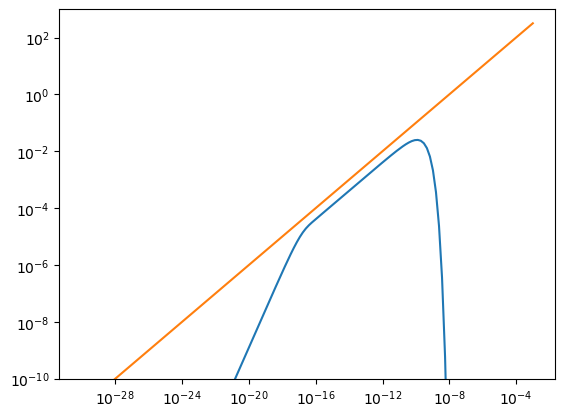

In [78]:
plt.ylim(1e-10, 1e3)
plt.loglog(E_ph, E_ph*q_vec)
plt.loglog(E_ph, 10000*np.power(E_ph, 0.5))

In [ ]:
def calcular_emisividad(P, N, E, E_ph, B):
    """
    Calcula una integral definida usando el método del simpson.
    
    Parámetros:
    - P: Potencia emitida por particula
    - N: Numero de particulas para una dada energia
    - E: array de energias
    - E_ph: Energia del foton emitido
    - B: Magnitud del campo magnetico
    """
    
    if len(E) % 2 != 0:
        raise ValueError("El número de subintervalos debe ser par para la regla de Simpson.")
    # Definimos el producto que va en la integral
    y = P(E_ph,E,B)[0][:][0]*N
    
    # Aplicar la regla de Simpson
    h = (np.max(E) - np.min(E)) / (len(E))
    integral = h / 3 * (y[0] + 4 * np.sum(y[1:len(E):2]) + 2 * np.sum(y[2:len(E)-1:2]) + y[-1])
    return integral

E = np.linspace(1e-3, 1e6, 3000)  # Energia de las particulas
E_ph = np.linspace(1e-3, 1e1, 50)  # Energia de los fotones
B = np.linspace(1e6, 6e6, 6)  # magnitud del campo magnetico

print(B)

N=1e5*E**-2
j = np.empty((len(E_ph), len(B))) 
for i, energy in enumerate(E_ph):
    for k, magnitude in enumerate(B):
        j[i,k]+=1/(4*np.pi)*calcular_emisividad(PowerFunctionSYNC,N,E,energy,magnitude)

print(j.shape)



[1000000. 2000000. 3000000. 4000000. 5000000. 6000000.]
(50, 6)


In [102]:
import pandas as pd

df= pd.DataFrame(j, columns=B, index=E_ph)

df

,1000000.0,2000000.0,3000000.0,4000000.0,5000000.0,6000000.0
0.001000,8.457203e+08,2.877463e+09,1.473458e+10,1.021715e+11,8.713057e+11,8.572910e+12
0.205061,5.099117e-310,2.137793e-05,9.224894e+02,1.264593e+06,4.443114e+07,3.185336e+08
0.409122,6.945717e-310,6.945788e-310,1.244745e-13,4.900591e-05,2.663774e+00,1.987432e+03
0.613184,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.477733e-10,7.692700e-05
0.817245,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,2.748017e-13
1.021306,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310
1.225367,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310
1.429429,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310
1.633490,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310
1.837551,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310,6.945788e-310


<function matplotlib.pyplot.show(close=None, block=None)>

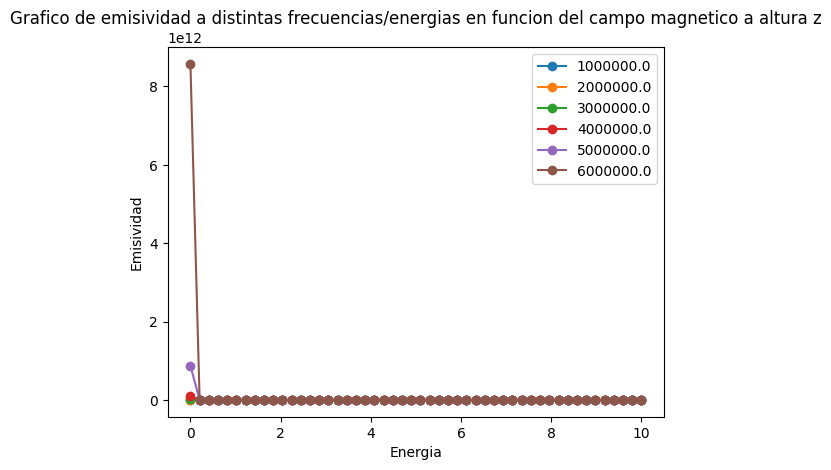

In [103]:
import matplotlib.pyplot as plt

#df.drop(columns=[5000000.0], inplace=True)
df.plot(kind='line', marker='o')
plt.title('Grafico de emisividad a distintas frecuencias/energias en funcion del campo magnetico a altura z')
plt.xlabel('Energia')
plt.ylabel('Emisividad')
plt.show

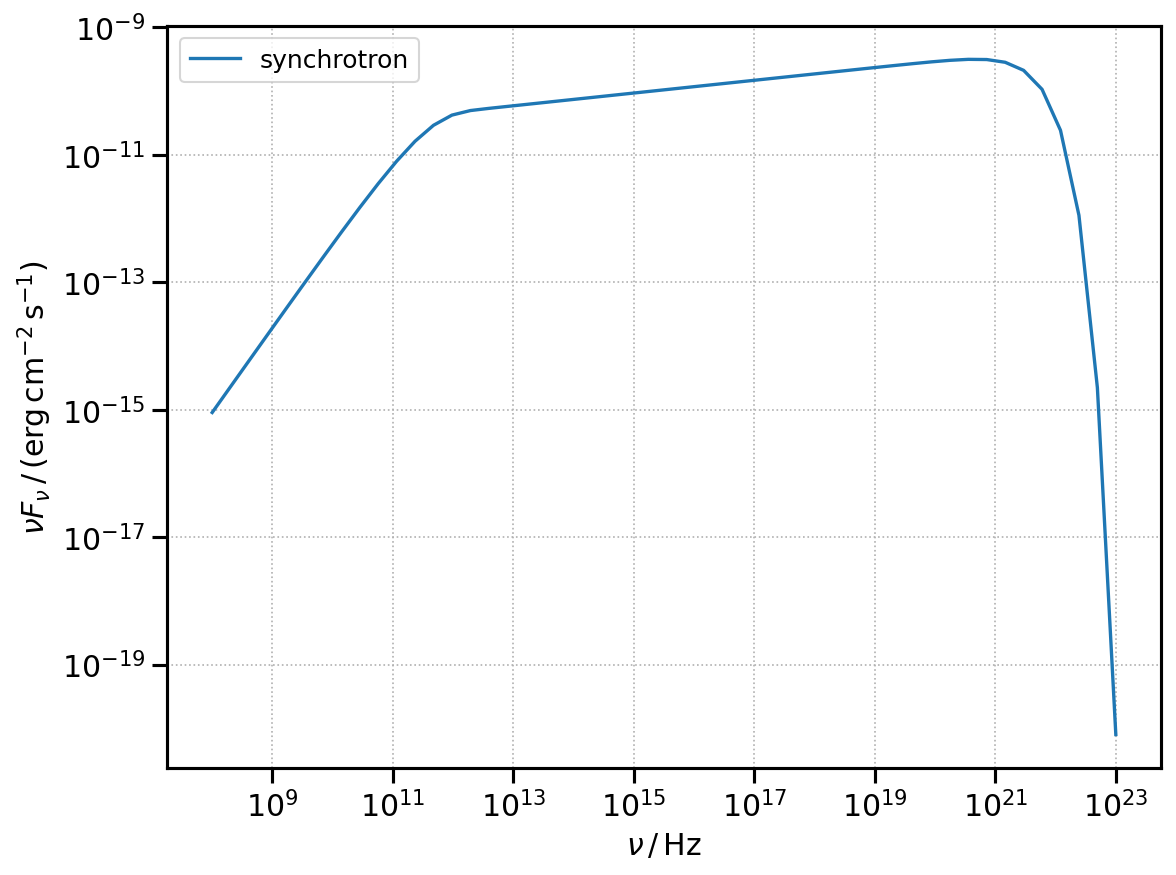

In [79]:
import numpy as np
import astropy.units as u
from astropy.constants import m_e
from astropy.coordinates import Distance
from agnpy.spectra import PowerLaw
from agnpy.emission_regions import Blob
from agnpy.synchrotron import Synchrotron
from agnpy.utils.plot import load_mpl_rc, plot_sed
import matplotlib.pyplot as plt


# set the quantities defining the blob
R_b = 1e16 * u.cm
V_b = 4 / 3 * np.pi * R_b ** 3
z = Distance(1e27, unit=u.cm).z
delta_D = 10
Gamma = 10
B = 1 * u.G

# electron distribution
W_e = 1e48 * u.erg # total energy in electrons

n_e = PowerLaw.from_total_energy(
    W_e,
    V_b,
    p=2.8,
    gamma_min=1e2,
    gamma_max=1e7,
    mass=m_e,
)

# define the emission region and the radiative process
blob = Blob(R_b, z, delta_D, Gamma, B, n_e=n_e)
synch = Synchrotron(blob)

# compute the SED over an array of frequencies
nu = np.logspace(8, 23) * u.Hz
sed = synch.sed_flux(nu)

# load matplotlib configuration for agnpy
load_mpl_rc()

plot_sed(nu, sed, label="synchrotron")
plt.show()